In [ ]:
import numpy as np
import pandas as pd
from numba import njit
import matplotlib.pyplot as plt

In [ ]:
@njit
def zscore(x: np.ndarray, window: int) -> np.ndarray:
    n = len(x)
    result = np.full(n, np.nan)
    for i in range(window, n):
        window_slice = x[i - window:i]
        mean = np.mean(window_slice)
        std = np.std(window_slice)
        if std != 0:
            result[i] = (x[i] - mean) / std
    return result

@njit
def rolling_corr(x: np.ndarray, y: np.ndarray, window: int) -> np.ndarray:
    n = len(x)
    result = np.full(n, np.nan)
    for i in range(window, n):
        x_win = x[i - window:i]
        y_win = y[i - window:i]
        x_mean = np.mean(x_win)
        y_mean = np.mean(y_win)
        cov = np.mean((x_win - x_mean) * (y_win - y_mean))
        std_x = np.std(x_win)
        std_y = np.std(y_win)
        if std_x != 0 and std_y != 0:
            result[i] = cov / (std_x * std_y)
    return result

@njit
def count_concordant_discordant(x, y):
    n = len(x)
    conc = 0
    disc = 0
    for i in range(n):
        for j in range(i + 1, n):
            dx = x[j] - x[i]
            dy = y[j] - y[i]
            prod = dx * dy
            if prod > 0:
                conc += 1
            elif prod < 0:
                disc += 1
    return conc, disc

@njit
def rolling_kendall_tau(x: np.ndarray, y: np.ndarray, window: int) -> np.ndarray:
    n = len(x)
    result = np.full(n, np.nan)
    for i in range(window, n):
        x_win = x[i - window:i]
        y_win = y[i - window:i]
        conc, disc = count_concordant_discordant(x_win, y_win)
        denom = conc + disc
        if denom > 0:
            result[i] = (conc - disc) / denom
    return result

@njit
def percentile(data: np.ndarray, perc: float) -> float:
    data = data[~np.isnan(data)]
    n = len(data)
    if n == 0:
        return np.nan
    sorted_data = np.sort(data)
    k = int(np.round(perc * (n - 1)))
    return sorted_data[k]

@njit
def compute_join_rets(btc_close: np.ndarray, eth_close: np.ndarray) -> np.ndarray:
    n = len(btc_close)
    join_rets = np.empty(n)
    for i in range(n):
        if btc_close[i] > 0 and eth_close[i] > 0:
            join_rets[i] = np.log(btc_close[i]) - np.log(eth_close[i])
        else:
            join_rets[i] = 0.0
    return join_rets

@njit
def kelly_numba(rets: np.ndarray, f_length: int = 10, s_length: int = 30, fraction: float = 0.5) -> np.ndarray:
    n = len(rets)
    k = np.empty(n)
    k[:] = 0.1  # default value

    # Precompute weights for EMA
    alpha = 2.0 / (f_length + 1.0)

    # Arrays for EMA volatility
    ema_mean = 0.0
    ema_m2 = 0.0
    initialized = False

    for i in range(n):
        # --- EMA volatility ---
        if not initialized:
            ema_mean = rets[i]
            ema_m2 = 0.0
            initialized = True
        else:
            delta = rets[i] - ema_mean
            ema_mean += alpha * delta
            ema_m2 = (1 - alpha) * ema_m2 + alpha * delta * delta
        f_std = np.sqrt(ema_m2) if i >= 1 else 0.0

        # --- Rolling std volatility ---
        s_std = 0.0
        if i >= s_length:
            window = rets[i - s_length + 1:i + 1]
            mean_w = np.mean(window)
            var_w = 0.0
            for j in range(s_length):
                var_w += (window[j] - mean_w) ** 2
            s_std = np.sqrt(var_w / s_length)

        # --- Kelly fraction ---
        if f_std > 0 and s_std > 0:
            k[i] = (f_std / s_std) * fraction
        else:
            k[i] = 0.1

        # Clamp between 0.1 and 1
        if k[i] < 0.1:
            k[i] = 0.1
        elif k[i] > 1.0:
            k[i] = 1.0

    return k

In [ ]:
@njit
def run_strategy(btc_close: np.ndarray, eth_close: np.ndarray,
                 entry_z_percentile: float = 0.99, min_z_threshold: float = 0.4,
                 corr_window_short: int = 10, corr_window_long: int = 60,
                 miss_price_threshold: float = 0.3, fee_rate: float = 0.001,
                 mode: str = "long_long",
                 init_capital: float = 100_000,
                 entry_pct: float = 0.1) -> tuple:

    n = len(btc_close)
    position = 0
    capital = init_capital
    cum_pnl = np.zeros(n)
    capital_curve = np.zeros(n)
    pnls = np.zeros(n)
    entry_thresh_ = np.zeros(n)
    entry_signal = np.zeros(n)
    exit_signal = np.zeros(n)

    # Position variables
    entry_price_btc = 0.0
    entry_price_eth = 0.0
    qty_btc = 0.0
    qty_eth = 0.0

    spread = btc_close - eth_close
    z_spread = zscore(spread, corr_window_long)

    corr_short = rolling_corr(btc_close, eth_close, corr_window_short)
    corr_long = rolling_corr(btc_close, eth_close, corr_window_long)
    corr_short_kendall = rolling_kendall_tau(btc_close, eth_close, corr_window_short)
    corr_long_kendall = rolling_kendall_tau(btc_close, eth_close, corr_window_long)
    join_rets = compute_join_rets(btc_close, eth_close)
    kelly = kelly_numba(join_rets, 30, 365, 1)

    for i in range(n):
        # Default: capital curve = realized pnl
        capital_curve[i] = capital
        cum_pnl[i] = capital - init_capital
        curr_kelly = kelly[i]

        if (
            np.isnan(corr_short[i]) or np.isnan(corr_long[i]) or
            np.isnan(z_spread[i]) or i < 100
        ):
            continue

        # Dynamic threshold
        recent_kendalls = corr_long_kendall[max(0, i - corr_window_long):i]
        recent_pearson = corr_long[max(0, i - corr_window_long):i]
        entry_thresh = percentile(recent_kendalls, entry_z_percentile) * 0.5 + percentile(recent_pearson, 0.5) * 0.5
        entry_thresh = max(entry_thresh, min_z_threshold)
        entry_thresh_[i] = entry_thresh

        thresh_hold = miss_price_threshold * 0.7 + entry_thresh * 0.2
        
        # Entry/Exit signals
        score = (corr_long[i] - corr_short[i]) + (corr_long_kendall[i] - corr_short_kendall[i])
        signal_entry = (score > thresh_hold*2) and (z_spread[i] > entry_thresh)

        signal_exit = (
            (corr_short[i] > corr_long[i]) and
            (corr_short_kendall[i] > corr_long_kendall[i]) and
            (-z_spread[i] > entry_thresh)
        )

        # === ENTRY ===
        if position == 0 and signal_entry:
            entry_price_btc = btc_close[i]
            entry_price_eth = eth_close[i]

            # Allocate capital
            alloc_btc = capital * entry_pct * curr_kelly
            alloc_eth = capital * entry_pct * curr_kelly
            qty_btc = alloc_btc / entry_price_btc
            qty_eth = alloc_eth / entry_price_eth

            # Deduct fees
            entry_fee = fee_rate * (alloc_btc + alloc_eth)
            capital -= entry_fee

            position = 1
            entry_signal[i] = 1

        # === EXIT ===
        elif position == 1 and signal_exit:
            exit_price_btc = btc_close[i]
            exit_price_eth = eth_close[i]

            # Compute realized PnL
            if mode == "long_short":
                pnl = (exit_price_btc - entry_price_btc) * qty_btc \
                      + (entry_price_eth - exit_price_eth) * qty_eth
            elif mode == "long_long":
                pnl = (exit_price_btc - entry_price_btc) * qty_btc \
                      + (exit_price_eth - entry_price_eth) * qty_eth
            elif mode == "short_short":
                pnl = (entry_price_btc - exit_price_btc) * qty_btc \
                      + (entry_price_eth - exit_price_eth) * qty_eth

            # Deduct exit fee
            exit_fee = fee_rate * (exit_price_btc * qty_btc + exit_price_eth * qty_eth)
            pnl -= exit_fee

            # Update realized capital
            capital += pnl
            pnls[i] = pnl
            position = 0
            qty_btc = qty_eth = 0.0
            entry_price_btc = entry_price_eth = 0.0
            exit_signal[i] = 1

        # === UNREALIZED PNL TRACKING ===
        if position == 1:
            cur_btc = btc_close[i]
            cur_eth = eth_close[i]
            if mode == "long_short":
                unrealized = (cur_btc - entry_price_btc) * qty_btc \
                             + (entry_price_eth - cur_eth) * qty_eth
            elif mode == "long_long":
                unrealized = (cur_btc - entry_price_btc) * qty_btc \
                             + (cur_eth - entry_price_eth) * qty_eth
            elif mode == "short_short":
                unrealized = (entry_price_btc - cur_btc) * qty_btc \
                             + (entry_price_eth - cur_eth) * qty_eth

            capital_curve[i] = capital + unrealized if position==1 else capital
            cum_pnl[i] = capital_curve[i] - init_capital

    return pnls, capital_curve, z_spread, entry_thresh_, corr_short, corr_long, entry_signal, exit_signal

In [ ]:
# --- Data Preparation Example
def prepare_data(btc_df: pd.DataFrame, eth_df: pd.DataFrame) -> pd.DataFrame:
    btc_df = btc_df.rename(columns={'open_time': 'Date', 'close': 'BTC_Close'})
    eth_df = eth_df.rename(columns={'open_time': 'Date', 'close': 'ETH_Close'})
    merged = pd.merge(btc_df[['Date', 'BTC_Close']], eth_df[['Date', 'ETH_Close']], on='Date')
    merged['Date'] = pd.to_datetime(merged['Date'], unit='ms')
    return merged

def optimize_params(train_btc, train_eth,
                    run_strategy_func,
                    short_windows=[20],
                    long_windows=[100],
                    min_z_vals=[0.6],
                    miss_p_vals = np.arange(0.3, 0.36, 0.01),
                    entry_z_percentile=0.9,
                    fee_rate=0.0005,
                    init_capital=100000,
                    entry_pct=0.5,
                    mode="long_long",
                    top_n=10):
    """
    Runs a grid search to find the optimal hyperparameters for the strategy.
    Returns top_n results and a dict of all train capital curves.
    """

    results = []
    train_curve_dict = {}
    
    for sw in short_windows:
        for lw in long_windows:
            if lw <= sw:
                continue
            for mz in min_z_vals:
                for mp in miss_p_vals:
                    pnl, cap_curve, *_ = run_strategy_func(
                        train_btc, train_eth,
                        entry_z_percentile=entry_z_percentile,
                        min_z_threshold=mz,
                        corr_window_short=sw,
                        corr_window_long=lw,
                        miss_price_threshold=mp,
                        fee_rate=fee_rate,
                        mode=mode,
                        init_capital=init_capital,
                        entry_pct=entry_pct
                    )
                    sharpe = (np.mean(np.diff(cap_curve) / cap_curve[:-1]) /
                            np.std(np.diff(cap_curve) / cap_curve[:-1]) *
                            np.sqrt(365*24)) if len(cap_curve) > 1 else 0
                    results.append({
                        "short_window": sw,
                        "long_window": lw,
                        "min_z": mz,
                        "miss_price": mp,
                        "sharpe": sharpe,
                        "final_capital": cap_curve[-1]
                    })
                    train_curve_dict[(sw, lw, mz, mp)] = cap_curve

    df_results = pd.DataFrame(results)
    df_top = df_results.sort_values(by="sharpe", ascending=False).head(top_n)

    return df_top, train_curve_dict

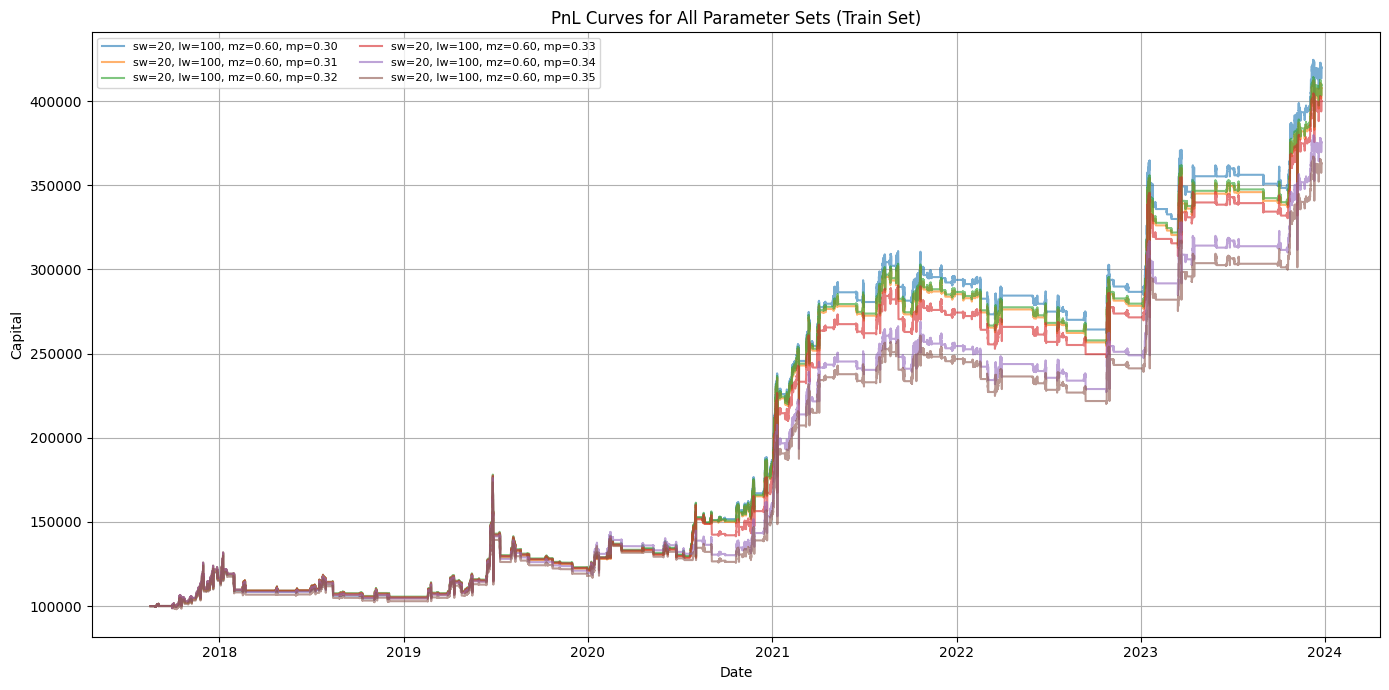

Top parameter sets:
   short_window  long_window  min_z  miss_price    sharpe  final_capital
0            20          100    0.6        0.30  0.793144  419887.763759
2            20          100    0.6        0.32  0.782183  409647.324465
1            20          100    0.6        0.31  0.781079  407753.763982
3            20          100    0.6        0.33  0.767451  400097.697052
4            20          100    0.6        0.34  0.747194  375507.754240
5            20          100    0.6        0.35  0.734238  363037.818043


In [ ]:
import joblib
# === Load Data ===
ticker_data = joblib.load("/Users/leoinv/Documents/CODE/BACKTEST/data/1h.joblib")
btc = ticker_data["BTCUSDT"]
eth = ticker_data["ETHUSDT"]

btc = btc.reset_index()
eth = eth.reset_index()

# Prepare your aligned df
df = prepare_data(btc, eth)
btc_close = df['BTC_Close'].values
eth_close = df['ETH_Close'].values

# --- Split train/test ---
split_idx = int(len(btc_close) * 0.8)
train_btc = btc_close[:split_idx]
train_eth = eth_close[:split_idx]
test_btc = btc_close[split_idx:]
test_eth = eth_close[split_idx:]

# Optimize and get train curves
top_params, train_curve_dict = optimize_params(train_btc, train_eth, run_strategy, top_n=6, fee_rate=0)

# === Plot TRAIN curves ===
train_dates = df['Date'].values[:split_idx]
plt.figure(figsize=(14, 7))
for params, curve in train_curve_dict.items():
    label = f"sw={params[0]}, lw={params[1]}, mz={params[2]:.2f}, mp={params[3]:.2f}"
    plt.plot(train_dates, curve, label=label, alpha=0.6)
plt.title("PnL Curves for All Parameter Sets (Train Set)")
plt.xlabel("Date")
plt.ylabel("Capital")
plt.legend(fontsize=8, loc='upper left', ncol=2)
plt.grid(True)
plt.tight_layout()
plt.show()

# === Run test curves with top_params as before ===
# (your existing test code unchanged)

print("Top parameter sets:")
print(top_params)

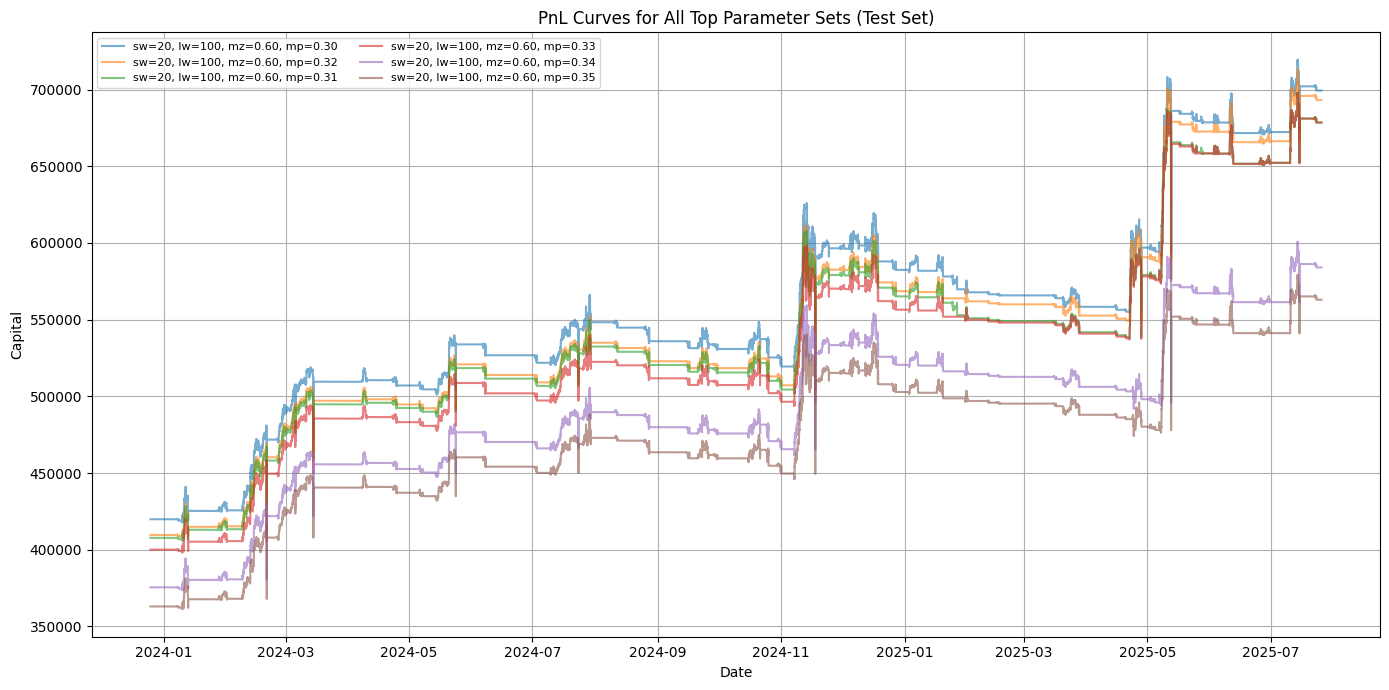

In [ ]:
# --- Split test data ---
test_btc = btc_close[split_idx:]
test_eth = eth_close[split_idx:]

# Store test results
test_results = []
capital_curve_dict = {}

for _, row in top_params.iterrows():
    sw = int(row["short_window"])
    lw = int(row["long_window"])
    mz = row["min_z"]
    mp = row["miss_price"]
    capital = row["final_capital"]

    pnl, capital_curve, *_ = run_strategy(
        test_btc, test_eth,
        entry_z_percentile=0.8,
        min_z_threshold=mz,
        corr_window_short=sw,
        corr_window_long=lw,
        miss_price_threshold=mp,
        fee_rate=0.0005,
        mode="long_long",
        init_capital=capital,
        entry_pct=0.5
    )

    capital_curve_dict[(sw, lw, mz, mp)] = capital_curve
    
    final_capital = capital_curve[-1]
    sharpe = (np.mean(np.diff(capital_curve) / capital_curve[:-1]) /
              np.std(np.diff(capital_curve) / capital_curve[:-1]) *
              np.sqrt(365*24)) if len(capital_curve) > 1 else 0

    test_results.append({
        "short_window": sw,
        "long_window": lw,
        "min_z": mz,
        "miss_price": mp,
        "final_capital": final_capital,
        "sharpe": sharpe
    })


# Create date index for test set
test_dates = df['Date'].values[split_idx:]

plt.figure(figsize=(14, 7))

# Plot each capital curve with date index
for params, curve in capital_curve_dict.items():
    label = f"sw={params[0]}, lw={params[1]}, mz={params[2]:.2f}, mp={params[3]:.2f}"
    plt.plot(test_dates, curve, label=label, alpha=0.6)

plt.title("PnL Curves for All Top Parameter Sets (Test Set)")
plt.xlabel("Date")
plt.ylabel("Capital")
plt.legend(fontsize=8, loc='upper left', ncol=2)
plt.grid(True)
plt.tight_layout()
plt.show()

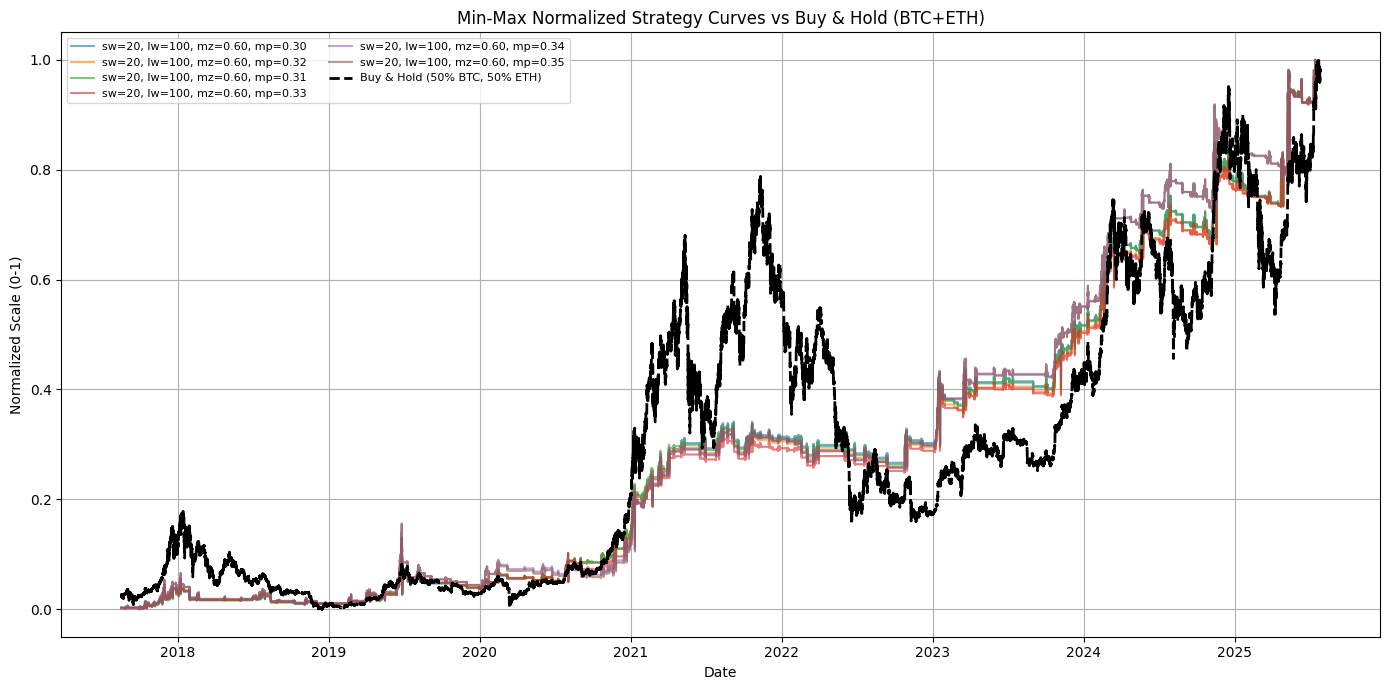

In [ ]:
# --- Buy & Hold curve (50% BTC, 50% ETH) ---
initial_capital = 100_000
btc_full = btc_close
eth_full = eth_close
bnh_curve = (
    initial_capital * 0.5 * (btc_full / btc_full[0]) +
    initial_capital * 0.5 * (eth_full / eth_full[0])
)

# --- Concatenate train and test curves ---
full_curve_dict = {}
for params in top_params.itertuples(index=False):
    key = (int(params.short_window), int(params.long_window), params.min_z, params.miss_price)
    
    train_curve = train_curve_dict[key]
    test_curve = capital_curve_dict[key]
    
    offset = train_curve[-1] - test_curve[0]
    test_curve_adj = test_curve + offset
    
    full_curve = np.concatenate([train_curve, test_curve_adj])
    full_curve_dict[key] = full_curve

# --- Full date index ---
full_dates = pd.to_datetime(df['Date'].values)

# --- Reindex curves and apply Min-Max normalization ---
curves_df = pd.DataFrame(index=full_dates)

for params, curve in full_curve_dict.items():
    s = pd.Series(curve, index=full_dates[:len(curve)])
    s = s.reindex(full_dates).ffill()
    s = (s - s.min()) / (s.max() - s.min())  # <-- Min-Max normalization
    label = f"sw={params[0]}, lw={params[1]}, mz={params[2]:.2f}, mp={params[3]:.2f}"
    curves_df[label] = s

# --- Buy & Hold normalized (Min-Max) ---
bnh_series = pd.Series(bnh_curve, index=full_dates).reindex(full_dates).ffill()
bnh_series = (bnh_series - bnh_series.min()) / (bnh_series.max() - bnh_series.min())

# --- Plot normalized cumulative returns ---
plt.figure(figsize=(14, 7))

for col in curves_df.columns:
    plt.plot(curves_df.index, curves_df[col], label=col, alpha=0.6)

plt.plot(bnh_series.index, bnh_series, label="Buy & Hold (50% BTC, 50% ETH)", 
         color='black', linewidth=2, linestyle='--')

plt.title("Min-Max Normalized Strategy Curves vs Buy & Hold (BTC+ETH)")
plt.xlabel("Date")
plt.ylabel("Normalized Scale (0-1)")
plt.legend(fontsize=8, loc='upper left', ncol=2)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
from utils import performance_metrics
import pandas as pd

# --- Prepare comparison results ---
results = []

# Strategy curves
for params, curve in full_curve_dict.items():
    curve_series = pd.Series(curve, index=full_dates)
    perf = performance_metrics(curve_series, risk_free_rate=0.00, periods_per_year=365*24)
    
    results.append({
        "Strategy": f"sw={params[0]}, lw={params[1]}, mz={params[2]:.2f}, mp={params[3]:.2f}",
        **perf
    })

# Buy & Hold curve
bnh_series = pd.Series(bnh_curve, index=full_dates)
perf_bnh = performance_metrics(bnh_series, risk_free_rate=0.00, periods_per_year=365*24)

results.append({
    "Strategy": "Buy & Hold (50% BTC, 50% ETH)",
    **perf_bnh
})

# Convert to DataFrame
df_perf = pd.DataFrame(results)

# Sort by Sharpe (or any other metric)
df_perf = df_perf.sort_values(by="Sharpe Ratio", ascending=False)

print("===== Strategy vs Buy & Hold Performance =====")
df_perf

===== Strategy vs Buy & Hold Performance =====


,Strategy,CAR,Volatility,Sharpe Ratio,Max Drawdown,Calmar Ratio
0,"sw=20, lw=100, mz=0.60, mp=0.30",0.277945,0.364267,0.673289,-0.350155,0.793777
1,"sw=20, lw=100, mz=0.60, mp=0.32",0.276516,0.364581,0.669640,-0.350155,0.789694
2,"sw=20, lw=100, mz=0.60, mp=0.31",0.273082,0.363998,0.663312,-0.350155,0.779888
3,"sw=20, lw=100, mz=0.60, mp=0.33",0.273065,0.367994,0.656073,-0.350155,0.779840
4,"sw=20, lw=100, mz=0.60, mp=0.34",0.249228,0.360743,0.616863,-0.350155,0.711764
5,"sw=20, lw=100, mz=0.60, mp=0.35",0.243470,0.359571,0.606024,-0.350155,0.695319
6,"Buy & Hold (50% BTC, 50% ETH)",0.457449,0.782934,0.480612,-0.874701,0.522978
